## Data Pattern


| Feature | Observation |
| --- | --- |
| Maintenance events | Jumps to >100% (e.g., Mar 24 → 128%, Apr–Jun sustained >100%) |
| Degradation | Slow decline between maintenance events (~1% per few days) |
| Downtime (0%) | Runs of consecutive 0% (e.g., Jan 28 – Feb 18, Mar 3–10, Oct 5–8) |
| Partial days | Single-day dips to ~50% or ~33% (likely partial operation) |
| Date format | DD/MM/YYYY (day-first) |

Critical caveat: Since maintenance events are planned interventions, future jumps above 100% cannot be predicted from the data alone unless we know the maintenance schedule.\
The model can predict the natural degradation trend, but we must supply future maintenance dates as an input.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (14, 5)

# Load — note dayfirst=True because dates are DD/MM/YYYY
df = pd.read_csv("Pump_SE_CSV.csv", encoding="utf-8-sig", dayfirst=True)
df.columns = ["Date", "System Effectiveness"]

# Clean the percentage strings
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df["SE"] = df["System Effectiveness"].str.replace("%", "").astype(float)

df = df[["Date", "SE"]].sort_values("Date").reset_index(drop=True)
print(df.shape)
print(df.head())
print(df.tail())

(319, 2)
        Date    SE
0 2026-01-01  85.0
1 2026-01-02  84.0
2 2026-01-03  84.0
3 2026-01-04  84.0
4 2026-01-05  84.0
          Date    SE
314 2026-11-11  83.0
315 2026-11-12  83.0
316 2026-11-13  83.0
317 2026-11-14  83.0
318 2026-11-15  83.0


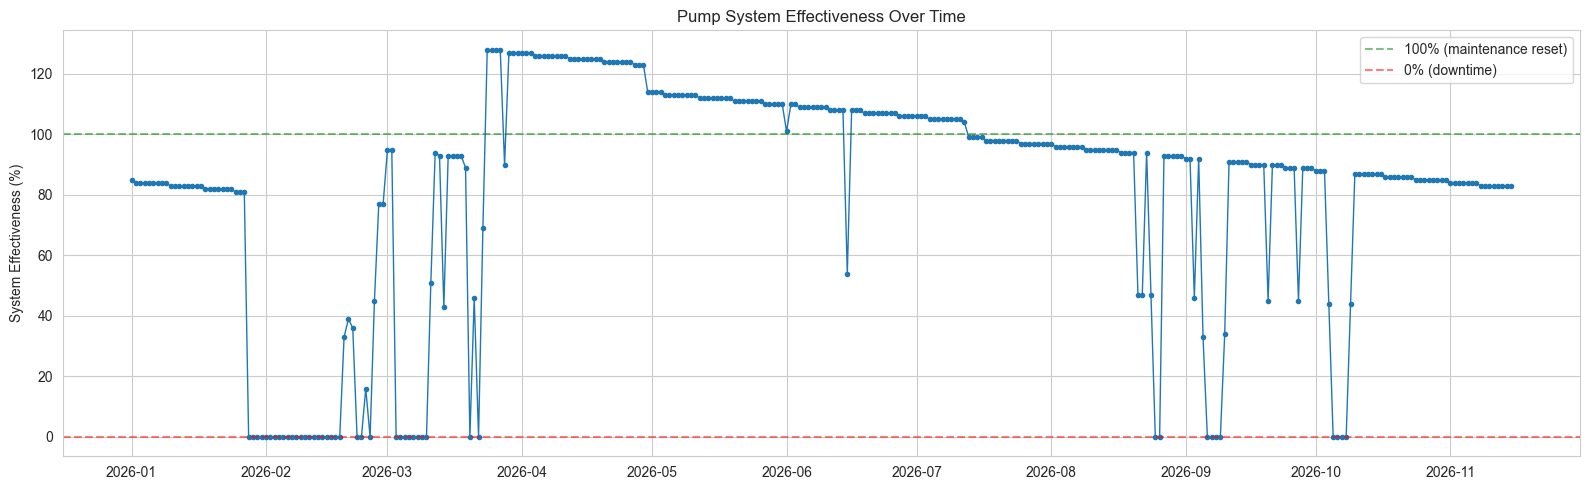

In [2]:
#EDA

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(df["Date"], df["SE"], marker=".", linewidth=1)
ax.axhline(100, color="green", linestyle="--", alpha=0.5, label="100% (maintenance reset)")
ax.axhline(0, color="red", linestyle="--", alpha=0.5, label="0% (downtime)")
ax.set_title("Pump System Effectiveness Over Time")
ax.set_ylabel("System Effectiveness (%)")
ax.legend()
plt.tight_layout()
plt.show()

We notice the pattern clearly: a long declining trend, a big maintenance event around late March, then a very long slow decline, punctuated by downtime clusters.

In [3]:
# Downtime days
print("Zero-SE days:", (df["SE"] == 0).sum())

# Maintenance jumps (day-over-day increase > 10 percentage points)
df["diff"] = df["SE"].diff()
jumps = df[df["diff"] > 10]
print("Maintenance jump events:")
print(jumps[["Date", "SE", "diff"]])

Zero-SE days: 45
Maintenance jump events:
          Date     SE  diff
49  2026-02-19   33.0  33.0
54  2026-02-24   16.0  16.0
56  2026-02-26   45.0  45.0
57  2026-02-27   77.0  32.0
59  2026-03-01   95.0  18.0
69  2026-03-11   51.0  51.0
70  2026-03-12   94.0  43.0
73  2026-03-15   93.0  50.0
79  2026-03-21   46.0  46.0
81  2026-03-23   69.0  69.0
82  2026-03-24  128.0  59.0
87  2026-03-29  127.0  37.0
166 2026-06-16  108.0  54.0
234 2026-08-23   94.0  47.0
238 2026-08-27   93.0  93.0
246 2026-09-04   92.0  46.0
252 2026-09-10   34.0  34.0
253 2026-09-11   91.0  57.0
263 2026-09-21   90.0  45.0
270 2026-09-28   89.0  44.0
281 2026-10-09   44.0  44.0
282 2026-10-10   87.0  43.0


In [4]:
#Feature Engineering
feat = df.copy()

# 1. Time index (days since start) — captures long-term trend
feat["t"] = (feat["Date"] - feat["Date"].min()).dt.days

# 2. Days since last maintenance (reset counter)
#    Maintenance = any day-over-day jump > 10 points OR SE > 100 after being < 100
feat["is_maint"] = ((feat["SE"].diff() > 10) | 
                    ((feat["SE"] > 100) & (feat["SE"].shift(1) < 100))).astype(int)
feat.loc[0, "is_maint"] = 0

days_since = []
counter = 0
for flag in feat["is_maint"]:
    counter = 0 if flag == 1 else counter + 1
    days_since.append(counter)
feat["days_since_maint"] = days_since

# 3. Calendar features
feat["month"] = feat["Date"].dt.month
feat["day_of_year"] = feat["Date"].dt.dayofyear
feat["day_of_week"] = feat["Date"].dt.dayofweek

# 4. Lag features (previous days' effectiveness)
for lag in [1, 2, 3, 7, 14]:
    feat["lag_" + str(lag)] = feat["SE"].shift(lag)

# 5. Rolling statistics (excluding current day)
feat["roll_mean_7"] = feat["SE"].shift(1).rolling(7).mean()
feat["roll_mean_14"] = feat["SE"].shift(1).rolling(14).mean()
feat["roll_std_7"] = feat["SE"].shift(1).rolling(7).std()

# 6. Recent downtime indicator (any zero in last 3 days)
feat["zero_last_3"] = (feat["SE"].shift(1).rolling(3).apply(lambda x: (x == 0).any()))

feat = feat.dropna().reset_index(drop=True)
print(feat.shape)
print(feat.columns.tolist())

(305, 18)
['Date', 'SE', 'diff', 't', 'is_maint', 'days_since_maint', 'month', 'day_of_year', 'day_of_week', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'roll_mean_7', 'roll_mean_14', 'roll_std_7', 'zero_last_3']


In [ ]:
feat.head()
# Note on the maintenance feature: This is the most important predictor. 
# When days_since_maint is small, SE tends to be high (post-maintenance); as it grows, SE declines.

,Date,SE,diff,t,is_maint,days_since_maint,month,day_of_year,day_of_week,lag_1,lag_2,lag_3,lag_7,lag_14,roll_mean_7,roll_mean_14,roll_std_7,zero_last_3
0,2026-01-15,83.0,0.0,14,0,15,1,15,3,83.0,83.0,83.0,84.0,85.0,83.285714,83.714286,0.487950,0.0
1,2026-01-16,83.0,0.0,15,0,16,1,16,4,83.0,83.0,83.0,84.0,84.0,83.142857,83.571429,0.377964,0.0
2,2026-01-17,83.0,0.0,16,0,17,1,17,5,83.0,83.0,83.0,83.0,84.0,83.000000,83.500000,0.000000,0.0
3,2026-01-18,82.0,-1.0,17,0,18,1,18,6,83.0,83.0,83.0,83.0,84.0,83.000000,83.428571,0.000000,0.0
4,2026-01-19,82.0,0.0,18,0,19,1,19,0,82.0,83.0,83.0,83.0,84.0,82.857143,83.285714,0.377964,0.0


In [6]:
# Never shuffle time series data. Use the last 30 days as a holdout to validate, mirroring your prediction horizon.
feature_cols = ["t", "days_since_maint", "month", "day_of_year", "day_of_week",
                "lag_1", "lag_2", "lag_3", "lag_7", "lag_14",
                "roll_mean_7", "roll_mean_14", "roll_std_7", "zero_last_3"]

X = feat[feature_cols]
y = feat["SE"]

# Hold out the final 30 days (Oct 17 – Nov 15) as test
split = len(feat) - 30
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
dates_test = feat["Date"].iloc[split:]

print(f"Train: {feat['Date'].iloc[0].date()} to {feat['Date'].iloc[split-1].date()} ({len(X_train)} rows)")
print(f"Test:  {dates_test.iloc[0].date()} to {dates_test.iloc[-1].date()} ({len(X_test)} rows)")

Train: 2026-01-15 to 2026-10-16 (275 rows)
Test:  2026-10-17 to 2026-11-15 (30 rows)


In [7]:
# Gradient boosting handles non-linear degradation, interactions between lags, and the maintenance counter well.
model = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    random_state=42
)
model.fit(X_train, y_train)

pred_test = model.predict(X_test)
pred_test = np.clip(pred_test, 0, 150)  # cap to plausible range

mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
print(f"Test MAE:  {mae:.2f} percentage points")
print(f"Test RMSE: {rmse:.2f} percentage points")

Test MAE:  23.40 percentage points
Test RMSE: 25.44 percentage points


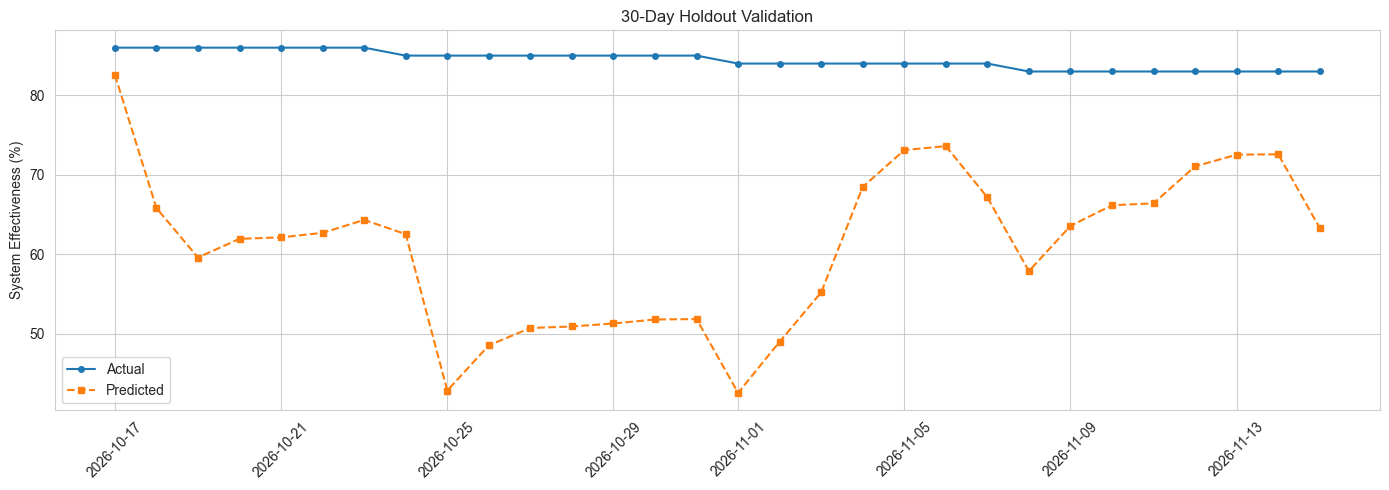

In [8]:
plt.figure(figsize=(14, 5))
plt.plot(dates_test, y_test.values, "o-", label="Actual", markersize=4)
plt.plot(dates_test, pred_test, "s--", label="Predicted", markersize=4)
plt.title("30-Day Holdout Validation")
plt.ylabel("System Effectiveness (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

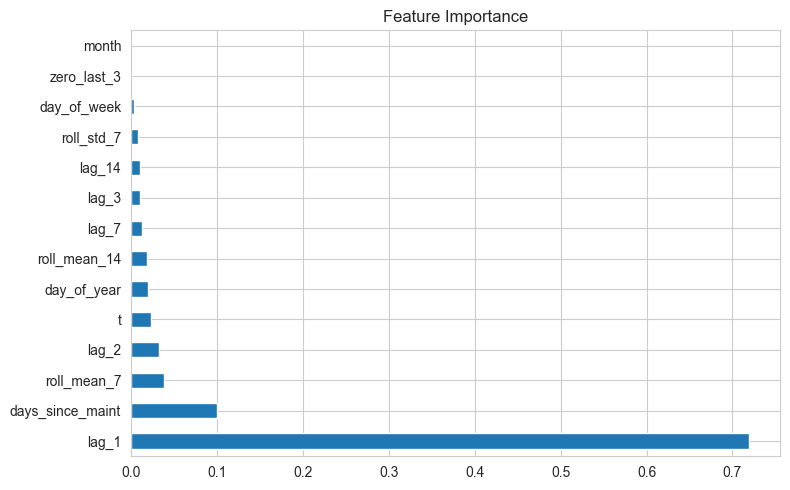

In [9]:
imp = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
imp.plot(kind="barh", figsize=(8, 5), title="Feature Importance")
plt.tight_layout()
plt.show()

In [10]:
def forecast(model, feat_history, n_days=30, future_maint_dates=None):
    """
    Iteratively forecast n_days ahead.
    feat_history: DataFrame with all engineered features (training data)
    future_maint_dates: set of Timestamps when maintenance is planned (optional)
    """
    if future_maint_dates is None:
        future_maint_dates = set()

    history = feat_history.copy()
    preds = []
    last_date = history["Date"].max()

    for step in range(1, n_days + 1):
        next_date = last_date + pd.Timedelta(days=step)

        # Build the feature row for this next date
        row = {}
        row["t"] = (next_date - feat_history["Date"].min()).days

        is_maint_today = next_date in future_maint_dates
        # days_since_maint: reset if maintenance today, else increment
        prev_dsm = history["days_since_maint"].iloc[-1]
        row["days_since_maint"] = 0 if is_maint_today else prev_dsm + 1

        row["month"] = next_date.month
        row["day_of_year"] = next_date.dayofyear
        row["day_of_week"] = next_date.dayofweek

        # Lags from the most recent known/forecast values
        se_series = history["SE"].values
        row["lag_1"] = se_series[-1]
        row["lag_2"] = se_series[-2]
        row["lag_3"] = se_series[-3]
        row["lag_7"] = se_series[-7]
        row["lag_14"] = se_series[-14]

        row["roll_mean_7"] = np.mean(se_series[-7:])
        row["roll_mean_14"] = np.mean(se_series[-14:])
        row["roll_std_7"] = np.std(se_series[-7:], ddof=1) if len(se_series) >= 7 else 0
        row["zero_last_3"] = int((se_series[-3:] == 0).any())

        X_next = pd.DataFrame([row])[feature_cols]
        y_next = model.predict(X_next)[0]

        # If maintenance is scheduled, force the post-maintenance jump (e.g., ~128%)
        if is_maint_today:
            y_next = 128.0

        y_next = float(np.clip(y_next, 0, 150))
        preds.append({"Date": next_date, "Predicted_SE": y_next,
                      "Maintenance": is_maint_today})

        # Append to history so next step uses this as a lag
        new_row = history.iloc[-1:].copy()
        new_row["Date"] = next_date
        new_row["SE"] = y_next
        new_row["days_since_maint"] = row["days_since_maint"]
        new_row["is_maint"] = int(is_maint_today)
        history = pd.concat([history, new_row], ignore_index=True)

    return pd.DataFrame(preds)

forecast_df = forecast(model, feat, n_days=30, future_maint_dates=set())
print(forecast_df.head(10))
print(forecast_df.tail(5))

        Date  Predicted_SE  Maintenance
0 2026-11-16     68.993525        False
1 2026-11-17     70.839222        False
2 2026-11-18     68.178725        False
3 2026-11-19     66.139002        False
4 2026-11-20     70.643107        False
5 2026-11-21     68.125734        False
6 2026-11-22     58.124516        False
7 2026-11-23     63.269852        False
8 2026-11-24     68.573609        False
9 2026-11-25     65.879786        False
         Date  Predicted_SE  Maintenance
25 2026-12-11     66.107434        False
26 2026-12-12     67.288790        False
27 2026-12-13     57.587973        False
28 2026-12-14     64.128417        False
29 2026-12-15     62.537718        False


In [ ]:
# If, for example, maintenance is scheduled for December 1, 2026:
maint_dates = {pd.Timestamp("2026-12-01")}
forecast_df = forecast(model, feat, n_days=30, future_maint_dates=maint_dates)

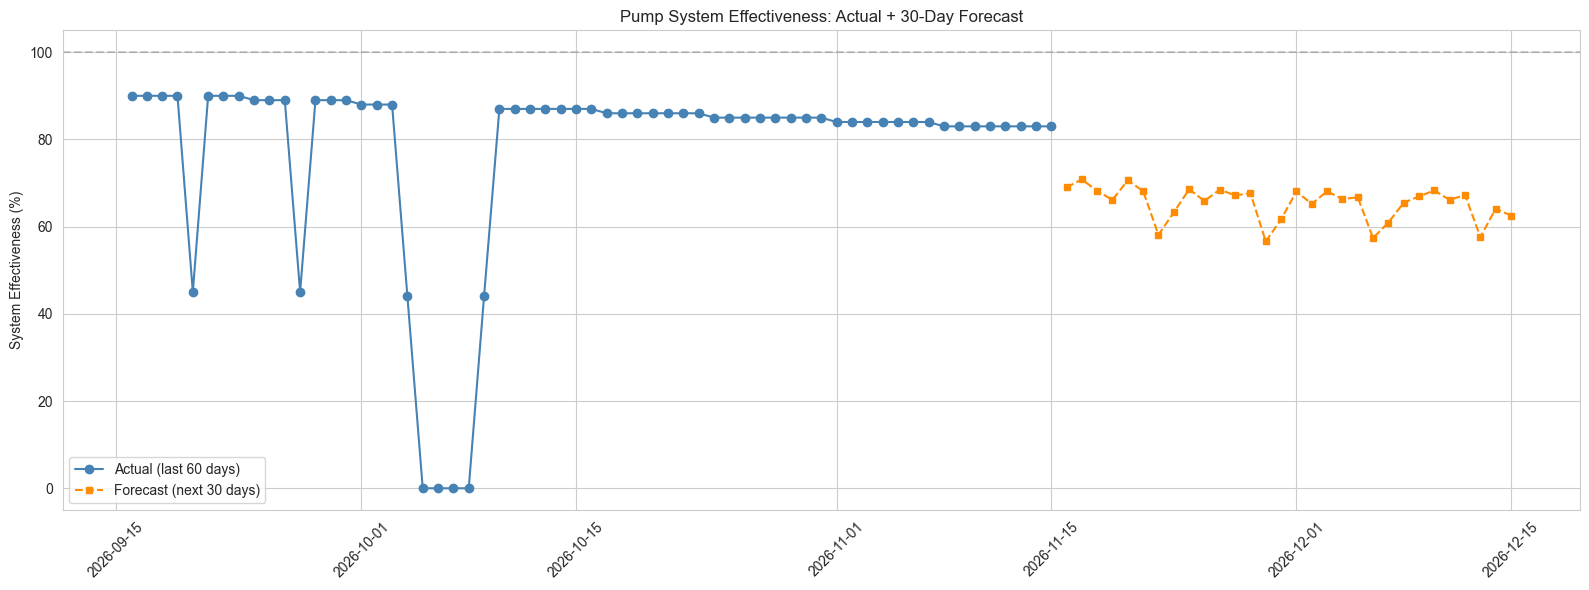

In [11]:
# Show last 60 days of actuals + 30 days forecast
recent = df[df["Date"] >= df["Date"].max() - pd.Timedelta(days=60)]

plt.figure(figsize=(16, 6))
plt.plot(recent["Date"], recent["SE"], "o-", label="Actual (last 60 days)", color="steelblue")
plt.plot(forecast_df["Date"], forecast_df["Predicted_SE"], "s--", 
         label="Forecast (next 30 days)", color="darkorange", markersize=5)

for _, r in forecast_df[forecast_df["Maintenance"]].iterrows():
    plt.axvline(r["Date"], color="green", linestyle=":", alpha=0.6)

plt.axhline(100, color="gray", linestyle="--", alpha=0.4)
plt.title("Pump System Effectiveness: Actual + 30-Day Forecast")
plt.ylabel("System Effectiveness (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()